# 02. Kiểm chứng dữ liệu

Notebook này trả lời chín câu hỏi ở cuối [01. Khảo sát dữ liệu](01_khao_sat_du_lieu.ipynb). Mỗi mục V01–V09 nêu câu hỏi, bảng cần đọc, cách kiểm tra và kết quả.

Khi chạy, notebook dùng các hàm kiểm chứng để tính trực tiếp từ CSV gốc. Notebook tự kiểm tra các phép tính và minh họa từ dữ liệu gốc. Bạn có thể đọc ngay các kết quả đã lưu dưới từng mục. “Đối chiếu đạt” nghĩa là hai cách tính từ dữ liệu cho cùng kết quả. Các bất thường trong dữ liệu được giải thích ở cuối từng mục.

## Mục lục

0. Chuẩn bị và xác nhận nguồn
1. V01 — Ngày đặt đơn có trước ngày đăng ký không?
2. V02 — Revenue, COGS, giảm giá và thanh toán khớp thế nào?
3. V03 — Trạng thái trả hàng, chi tiết trả và hoàn tiền có khớp không?
4. V04 — Lượng bán tồn kho và giao dịch có khớp theo tháng không?
5. V05 — `reorder_flag` có đủ hai lớp không?
6. V06 — Hai mã khuyến mãi xuất hiện và đi cùng giảm giá thế nào?
7. V07 — `bounce_rate` có khoảng giá trị và đơn vị gì?
8. V08 — Nhãn nguồn truy cập theo ngày được quan sát thế nào?
9. V09 — Lịch nộp dự báo có liên tục và tách khỏi Sales lịch sử không?
10. Tổng hợp đối chiếu và giới hạn

## 0. Chuẩn bị và xác nhận nguồn

Mỗi mục đọc các CSV cần thiết để tính lại câu trả lời. Notebook lấy SHA-256 của các CSV dùng trong V01–V09 ở đầu và cuối lượt chạy để phát hiện thay đổi.

Tiền được kiểm bằng `Decimal` và dung sai nghiệp vụ đã thống nhất.

In [4]:
from pathlib import Path
from decimal import Decimal
import gc

import math
import os
import platform
import sys

sys.dont_write_bytecode = True

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents)
             if (path / "notebook/ham_dung_chung.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")
sys.path.insert(0, str(ROOT / "notebook"))

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from ham_dung_chung import table_reader
read_table = table_reader().read_table

from ham_dung_chung import SOURCE_TABLES, file_sha, verification_checks

modules = verification_checks()
EXAMPLES_LIMIT = 20

pd.set_option('display.max_rows', 16)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda value: f'{value:,.6f}')
plt.rcParams.update({'figure.figsize': (10, 4), 'font.family': 'DejaVu Sans',
                     'axes.spines.top': False, 'axes.spines.right': False})

# display có sẵn trong Jupyter; fallback này cũng cho phép chạy code bằng Python thường.
try:
    display
except NameError:
    def display(value):
        print(value)

results = {}
illustration_checks = []

print(f'Gốc dự án: {ROOT}')
display(pd.DataFrame([{'Python': platform.python_version(), 'Pandas': pd.__version__,
                       'Matplotlib': matplotlib.__version__}]))

Gốc dự án: E:\SGU\Ky1_4\DA\DA_Datathon2026


,Python,Pandas,Matplotlib
0,3.11.7,2.2.3,3.10.1


In [5]:
def table(frame, title, columns=None, limit=12):
    selected = frame if columns is None else frame.loc[:, columns]
    print(f'{title} — hiển thị {min(limit, len(selected))}/{len(selected)} dòng tổng hợp/ví dụ')
    display(selected.head(limit).reset_index(drop=True))

def metric_table(metrics, names):
    display(pd.DataFrame([{'Chỉ tiêu': name, 'Tính từ CSV': metrics[name]} for name in names]))

def finish_figure(fig):
    fig.tight_layout()
    display(fig)
    plt.close(fig)

def verify_illustration(key, name, actual, expected):
    if isinstance(expected, float):
        matches = math.isclose(float(actual), expected, rel_tol=0, abs_tol=1e-9)
    else:
        matches = actual == expected
    assert matches, f'{key} — {name}: {actual!r} khác {expected!r}'
    illustration_checks.append({'Mục': key, 'Phép tính': name})

def register(key, metrics, reports, checks):
    failures = [name for name, passed in checks.items() if not passed]
    assert not failures, f'{key} có phép kiểm chưa đạt: {failures}'
    results[key] = {
        'Mục': key,
        'Chỉ tiêu đã tính': len(metrics),
        'Bảng đã tính': len(reports),
        'Phép kiểm kỹ thuật đạt': len(checks),
    }

def paths_for(key):
    return {name: ROOT / 'data/raw' / f'{name}.csv' for name in SOURCE_TABLES[key]}

required_paths = {path for key in SOURCE_TABLES for path in paths_for(key).values()}
missing = sorted(path.relative_to(ROOT).as_posix() for path in required_paths if not path.is_file())
if missing:
    raise FileNotFoundError("Thiếu CSV dùng để kiểm chứng: " + ", ".join(missing))
print(f'Có đủ {len(required_paths)} CSV dùng trong V01–V09.')


def source_snapshot():
    return {
        path.relative_to(ROOT).as_posix(): file_sha(path)
        for path in sorted(required_paths) if path.is_file()
    }

source_before = source_snapshot()


Có đủ 11 CSV dùng trong V01–V09.


## 1. V01 — Ngày đặt hàng và ngày đăng ký

**Mục tiêu:** xác định đơn trước/cùng/sau ngày đăng ký, số khách liên quan, độ lớn khoảng cách và độ phủ khóa nối.

**Bảng:** `orders.csv` (`order_id`, `customer_id`, `order_date`) và `customers.csv` (`customer_id`, `signup_date`).
Đơn là đơn vị đếm; số khách là số `customer_id` khác nhau trong nhóm đơn trước đăng ký.

**Phương pháp:** dùng `check_v01_dates.analyze`; `order_date` theo `%Y-%m-%d`, `signup_date` theo `%m/%d/%Y`.
Nối trái `many_to_one` theo ID chuỗi, không ghép NULL với NULL. Khóa khách trùng gây dừng; dòng không so sánh được có lý do loại trừ riêng.

Với đơn $i$, $d_i^{\mathrm{order}}$ là ngày đặt đơn và $d_i^{\mathrm{signup}}$ là ngày đăng ký của khách.

$$
\Delta_i = d_i^{\mathrm{order}} - d_i^{\mathrm{signup}}
$$

Số đơn đặt trước ngày đăng ký được tính trên những đơn có đủ thông tin để so sánh. Ký hiệu $\mathbf{1}$ bằng 1 khi điều kiện đúng, bằng 0 trong trường hợp còn lại.

$$
N_{\mathrm{before}} = \sum_i \mathbf{1}(\Delta_i < 0)
$$

Gọi $N_{\mathrm{orders}}$ là tổng số đơn. Tỷ lệ đơn trước đăng ký trên toàn bộ đơn hàng, tính theo phần trăm, là

$$
R_{\mathrm{before}} = 100 \times \frac{N_{\mathrm{before}}}{N_{\mathrm{orders}}}
$$

Trong nhóm trước đăng ký, $gap_i=-\Delta_i$ (ngày); tính trung bình, trung vị và phân vị nội suy tuyến tính.
Ô minh họa dựng lại phép nối và phân loại từ hai bảng nguồn, rồi đối chiếu với kết quả module.


In [6]:
v = modules['V01']
sources = {name: read_table(path) for name, path in paths_for('V01').items()}
metrics, checks, reports = v.analyze(**sources, examples=EXAMPLES_LIMIT)
register('V01', metrics, reports, checks)

joined = sources['orders'][['order_id', 'customer_id', 'order_date']].merge(
    sources['customers'][['customer_id', 'signup_date']].dropna(subset=['customer_id']),
    on='customer_id', how='left', validate='many_to_one', indicator=True)
order_dates, _ = v.parse_date(joined.order_date, 'order_date')
signup_dates, _ = v.parse_date(joined.signup_date, 'signup_date')
comparable = joined.customer_id.notna() & joined['_merge'].eq('both') & order_dates.notna() & signup_dates.notna()
delta = (order_dates - signup_dates).dt.days
before = comparable & delta.lt(0)
verify_illustration('V01', 'đơn trước signup', int(before.sum()), metrics['before_orders'])
verify_illustration('V01', 'khách có đơn trước signup', int(joined.loc[before, 'customer_id'].nunique()),
                    metrics['customers_with_before_orders'])
verify_illustration('V01', 'gap trung bình', float((-delta[before]).mean()), metrics['before_gap_mean_days'])

,Chỉ tiêu,Tính từ CSV
0,orders_rows,"646,945.000000"
1,before_orders,"477,453.000000"
2,before_percent_all_orders,73.801173
3,equal_orders,149.000000
4,after_orders,"169,343.000000"
5,uncomparable_orders,0.000000
6,customers_with_before_orders,"80,623.000000"
7,before_gap_mean_days,"1,524.432688"
8,before_gap_median_days,"1,468.000000"
9,before_gap_max_days,"3,832.000000"


Định dạng và phạm vi ngày — hiển thị 2/2 dòng tổng hợp/ví dụ


,column,format,null_count,invalid_non_null_count,min_date,max_date
0,order_date,%Y-%m-%d,0,0,2012-07-04,2022-12-31
1,signup_date,%m/%d/%Y,0,0,2012-01-17,2022-12-31


Ví dụ khoảng cách lớn nhất, không phải mẫu ngẫu nhiên — hiển thị 5/20 dòng tổng hợp/ví dụ


,order_id,customer_id,order_date,signup_date,order_date_iso,signup_date_iso,gap_days
0,48,39584,2012-07-04,12/31/2022,2012-07-04,2022-12-31,3832
1,197,135998,2012-07-05,12/29/2022,2012-07-05,2022-12-29,3829
2,50,39739,2012-07-04,12/26/2022,2012-07-04,2022-12-26,3827
3,1037,150084,2012-07-10,12/31/2022,2012-07-10,2022-12-31,3826
4,1111,55223,2012-07-13,12/31/2022,2012-07-13,2022-12-31,3823


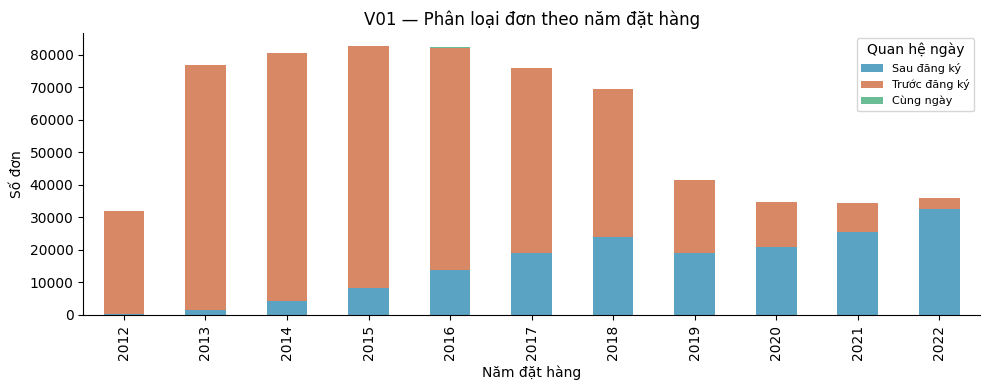

Có 477,453/646,945 đơn trước đăng ký (73.80%), thuộc 80,623 khách.


In [7]:
metric_table(metrics, ['orders_rows', 'before_orders', 'before_percent_all_orders', 'equal_orders',
                       'after_orders', 'uncomparable_orders', 'customers_with_before_orders',
                       'before_gap_mean_days', 'before_gap_median_days', 'before_gap_max_days'])
table(reports['date_validation'], 'Định dạng và phạm vi ngày',
      ['column', 'format', 'null_count', 'invalid_non_null_count', 'min_date', 'max_date'])
table(reports['largest_gaps'], 'Ví dụ khoảng cách lớn nhất, không phải mẫu ngẫu nhiên', limit=5)
annual = reports['time_distribution'].query("grouping == 'order_year'").pivot(
    index='order_year', columns='comparison', values='orders').fillna(0)
annual = annual.rename(columns={'before': 'Trước đăng ký', 'equal': 'Cùng ngày',
                                'after': 'Sau đăng ký', 'uncomparable': 'Không so sánh được'})
fig, ax = plt.subplots()
annual.plot.bar(stacked=True, ax=ax, color=['#5ba3c2', '#d98866', '#6bbd96'][:len(annual.columns)])
ax.set(title='V01 — Phân loại đơn theo năm đặt hàng', xlabel='Năm đặt hàng', ylabel='Số đơn')
ax.legend(title='Quan hệ ngày', fontsize=8)
finish_figure(fig)
print(f"Có {metrics['before_orders']:,}/{metrics['orders_rows']:,} đơn trước đăng ký "
      f"({metrics['before_percent_all_orders']:.2f}%), thuộc {metrics['customers_with_before_orders']:,} khách.")
del sources, joined, order_dates, signup_dates, comparable, delta, before, reports
gc.collect();

**Nhận xét và ý nghĩa:** tỷ lệ đơn trước đăng ký trong kết quả đặt ra nhu cầu làm rõ ý nghĩa `signup_date` trước khi dùng làm mốc vòng đời khách.
Không loại đơn hoặc sửa ngày từ quan sát này. Hai mẫu số “mọi đơn” và “đơn so sánh được” được module tách riêng.

**Chưa xác minh:** định nghĩa nghiệp vụ của ngày đăng ký, nguồn gốc/múi giờ ngày, tính ổn định của ID và khả năng chuyển đổi tài khoản.
Chuyển hệ thống hoặc thay đổi trạng thái tài khoản chỉ là giả thuyết; ngày trước đăng ký chưa đủ chứng minh dữ liệu sai.


## 2. V02 — Doanh thu, giảm giá, thanh toán và giá vốn

**Mục tiêu:** đối chiếu dòng hàng → đơn → ngày với `sales`, giữ đủ trạng thái đơn; phân biệt doanh thu gộp và tiền thanh toán.

**Bảng:** `orders.csv` (khóa/ngày/trạng thái), `order_items.csv` (số lượng, giá, giảm giá),
`payments.csv` (tiền thanh toán theo đơn), `products.csv` (giá vốn cung cấp), `sales.csv` (`Date`, `Revenue`, `COGS`).

**Phương pháp:** `check_v02_financials.read_sources/analyze/compact_reports`; kiểm tra khóa và FK, cộng con trước khi nối để tránh nhân bản.
Với dòng hàng $i$, đơn $o$ và ngày $d$:

$$G_o=\sum_{i\in o}q_i p_i,\quad D_o=\sum_{i\in o}discount_i,\quad
N_o=G_o-D_o,\quad C_o=\sum_{i\in o}q_i cogs_i.$$
$$P_o=\sum_{j\in o}payment_j;\qquad Revenue_d\stackrel{?}{=}\sum_{o\in d}G_o,\quad
COGS_d\stackrel{?}{=}\sum_{o\in d}C_o.$$

Kiểm tra $P_o\simeq N_o$ và $Revenue_d-\sum_{o\in d}P_o\simeq\sum_{o\in d}D_o$ với dung sai tuyệt đối `0.05`.
Không gọi mọi sai số khác 0 là không khớp; bảng so sánh phân biệt khớp tuyệt đối và khớp trong dung sai.


In [8]:
v = modules['V02']
sources = v.read_sources(paths_for('V02'))
metrics, checks, ledgers, fingerprints = v.analyze(**sources)
reports = v.compact_reports(metrics, ledgers, examples=EXAMPLES_LIMIT)
register('V02', metrics, reports, checks)

# Phép tính trực tiếp trên mọi dòng order_items; Decimal đọc từ chuỗi nguồn.
items = sources['order_items']
q = items.quantity.map(v.decimal_value)
p = items.unit_price.map(v.decimal_value)
discount = items.discount_amount.map(v.decimal_value)
gross_from_rows = sum(q * p, Decimal(0))
discount_from_rows = sum(discount, Decimal(0))
verify_illustration('V02', 'tổng q × giá', gross_from_rows, metrics['gross'])
verify_illustration('V02', 'tổng giảm giá', discount_from_rows, metrics['discount'])
verify_illustration('V02', 'gross − discount', gross_from_rows - discount_from_rows, metrics['net'])
verify_illustration('V02', 'tổng tiền thanh toán nguồn',
                    sum(sources['payments'].payment_value.map(v.decimal_value), Decimal(0)), metrics['payment'])

,Chỉ tiêu,Tính từ CSV
0,gross,16430476585.53
1,discount,749607320.10
2,payment,15680869265.43
3,net,15680869265.43
4,cogs,14163450519.14700961898794
5,sales_revenue,16430476585.53
6,sales_cogs,14163450519.17


Đối chiếu theo đơn, ngày và toàn kỳ — hiển thị 8/8 dòng tổng hợp/ví dụ


,comparison,compared_cases,missing_cases,exact_match_cases,within_tolerance_nonzero_cases,over_tolerance_count,max_abs_difference
0,order_payment_vs_gross_minus_discount,646945,0,646945,0,0,0.00
1,daily_revenue_vs_item_gross,3833,0,3833,0,0,0.00
2,daily_cogs_vs_quantity_product_cogs,3833,0,0,3833,0,0.0050662386432
3,daily_revenue_minus_payment_vs_discount,3833,0,3833,0,0,0.00
4,total_payment_vs_gross_minus_discount,1,0,1,0,0,0.00
5,total_revenue_vs_item_gross,1,0,1,0,0,0.00
6,total_cogs_vs_quantity_product_cogs,1,0,0,1,0,0.02299038101206
7,total_revenue_minus_payment_vs_discount,1,0,1,0,0,0.00


Đóng góp theo trạng thái đơn — giữ nguyên phạm vi — hiển thị 6/6 dòng tổng hợp/ví dụ


,order_status,orders,gross,discount,payment,cogs
0,cancelled,59462,1515891006.19,68877368.76,1447013637.43,1307337283.62299801278188
1,created,7275,190652330.76,8817311.99,181835018.77,165270549.14584947064768
2,delivered,516716,13117091360.41,598915403.21,12518175957.20,11304413900.82706797474332
3,paid,13577,345922854.99,15295758.75,330627096.24,298666030.94828700310808
4,returned,36142,907543031.93,41604316.34,865938715.59,782546526.55557601043376
5,shipped,13773,353376001.25,16097161.05,337278840.20,305216228.04723114727322


Ngày có chênh lệch khác 0 lớn nhất theo từng phép so sánh — hiển thị 1/1 dòng tổng hợp/ví dụ


,comparison,date,cogs,sales_cogs,daily_cogs_vs_quantity_product_cogs_difference
0,daily_cogs_vs_quantity_product_cogs,2015-03-28,5296480.6250662386432,5296480.62,-0.0050662386432


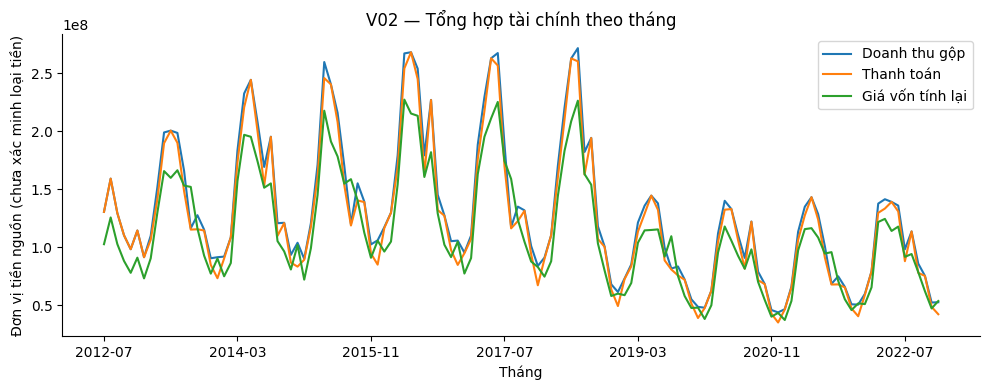

Chênh lệch tổng COGS (sales − tính từ dòng hàng): 0.02299038101206


In [9]:
metric_table(metrics, ['gross', 'discount', 'payment', 'net', 'cogs', 'sales_revenue', 'sales_cogs'])
table(reports['comparisons'], 'Đối chiếu theo đơn, ngày và toàn kỳ',
      ['comparison', 'compared_cases', 'missing_cases', 'exact_match_cases',
       'within_tolerance_nonzero_cases', 'over_tolerance_count', 'max_abs_difference'], limit=12)
table(reports['statuses'], 'Đóng góp theo trạng thái đơn — giữ nguyên phạm vi',
      ['order_status', 'orders', 'gross', 'discount', 'payment', 'cogs'])
table(reports['daily_max_difference_examples'], 'Ngày có chênh lệch khác 0 lớn nhất theo từng phép so sánh',
      ['comparison', 'date', 'cogs', 'sales_cogs', 'daily_cogs_vs_quantity_product_cogs_difference'], limit=3)
monthly = ledgers['daily'].assign(thang=lambda f: f.date.str[:7]).groupby('thang')[
    ['gross', 'payment', 'cogs']].sum().apply(lambda col: col.map(float))
fig, ax = plt.subplots()
monthly.rename(columns={'gross': 'Doanh thu gộp', 'payment': 'Thanh toán', 'cogs': 'Giá vốn tính lại'}).plot(ax=ax)
ax.set(title='V02 — Tổng hợp tài chính theo tháng', xlabel='Tháng', ylabel='Đơn vị tiền nguồn (chưa xác minh loại tiền)')
finish_figure(fig)
print('Chênh lệch tổng COGS (sales − tính từ dòng hàng):',
      Decimal(str(metrics['sales_cogs'])) - Decimal(str(metrics['cogs'])))
del sources, ledgers, reports, items, q, p, discount, fingerprints, monthly
gc.collect();

**Nhận xét và ý nghĩa:** các đối chiếu cho thấy `Revenue` theo giá trị gộp trước giảm giá; tiền thanh toán theo giá trị sau giảm giá.
`COGS` là giá vốn, không phải lợi nhuận. Cần giữ đúng định nghĩa này khi đọc chuỗi đích; chênh lệch nhỏ của giá vốn phải đọc cùng dung sai và quy tắc làm tròn.

**Chưa xác minh:** ghi nhận doanh thu kế toán, thời điểm thu tiền, quyết toán, hoàn tiền và loại tiền.
`payments` không có ngày giao dịch nên mọi tổng tiền theo ngày được phân bổ bằng `orders.order_date`.
`products.cogs` là giá vốn đang cung cấp; chưa tái lập giá vốn lịch sử. Sự khớp công thức trong bộ dữ liệu chưa xác nhận chính sách kế toán.


## 3. V03 — Trả hàng và hoàn tiền

**Mục tiêu:** kiểm tra khóa, thời gian, trạng thái, số lượng trả tích lũy, giới hạn tiền hoàn và các giả thuyết công thức hoàn tiền.

**Bảng:** `returns.csv`, `orders.csv`, `order_items.csv`, `payments.csv`.
Đơn vị quan sát gồm bản ghi trả hàng, cặp `(order_id, product_id)` và đơn hàng; không đánh đồng các mẫu số này.

**Phương pháp:** `check_v03_returns.read_sources/analyze/compact_reports`; cộng các lần trả và dòng mua theo cặp trước khi nối `one_to_one`,
không nối nhiều–nhiều và không xóa các cặp lặp. Với mỗi cặp:

$$Q_r=\sum return\_quantity,\quad Q_b=\sum quantity,\quad F=\sum refund\_amount.$$
$$GrossReturn=G\,Q_r/Q_b,\quad NetReturn=(G-D)\,Q_r/Q_b,$$
$$RefundRatio=F/GrossReturn,\quad DiscountRate=D/G,\quad lag=return\_date-order\_date.$$

Hai công thức giá trị trả là **giả thuyết phân bổ theo tỷ lệ**, không phải chính sách đã xác nhận.
Kiểm tra bằng nhau bằng $|a-b|\le0.05$; kiểm tra vượt trần bằng $a-b>0.05$; số lượng so chính xác.
Mẫu số không dương hoặc thanh toán thiếu được giữ chưa xác định. Pearson và thống kê tỷ lệ không trọng số, theo cặp.


In [10]:
v = modules['V03']
sources = v.read_sources(paths_for('V03'))
metrics, checks, ledgers, distributions, fingerprints = v.analyze(**sources)
reports, exceptions = v.compact_reports(metrics, ledgers, distributions, examples=EXAMPLES_LIMIT)
register('V03', metrics, reports, checks)

dated_returns = sources['returns'][['order_id', 'return_date']].merge(
    sources['orders'][['order_id', 'order_date']], on='order_id', how='left', validate='many_to_one')
lag = (pd.to_datetime(dated_returns.return_date, format='%Y-%m-%d')
       - pd.to_datetime(dated_returns.order_date, format='%Y-%m-%d')).dt.days
verify_illustration('V03', 'độ trễ trung vị từ ngày nguồn', float(lag.median()), metrics['lag_median_days'])
verify_illustration('V03', 'tổng tiền hoàn nguồn',
                    sum(sources['returns'].refund_amount.map(v.decimal_value), Decimal(0)), metrics['refund'])
demo = ledgers['pairs'].sort_values(v.PAIR).head(5).copy()
demo['GrossReturn tính lại'] = demo.gross * demo.returned_quantity / demo.purchased_quantity
demo['NetReturn tính lại'] = (demo.gross - demo.discount) * demo.returned_quantity / demo.purchased_quantity
verify_illustration('V03', 'công thức GrossReturn trên cặp minh họa',
                    demo['GrossReturn tính lại'].tolist(), demo.expected_gross_refund.tolist())

,Chỉ tiêu,Tính từ CSV
0,returns_rows,39939
1,return_orders,36062
2,return_pairs,39937
3,returned_orders_without_returns,80
4,full_return_pairs,13576
5,partial_return_pairs,26361
6,over_return_pairs,0
7,refund,510598506.55
8,refund_orders_above_payment,3640
9,refund_above_net_return,12658


Kiểm tra theo đúng cấp bản ghi/cặp/đơn — hiển thị 11/11 dòng tổng hợp/ví dụ


,section,comparison,compared_cases,matched_cases,mismatched_cases,tolerance,direction
0,V03.1,returns_on_nonreturned_status,39939,39939,0,0,upper_bound
1,V03.1,returned_orders_without_returns,646945,646865,80,0,upper_bound
2,V03.1,return_before_order,39939,39939,0,0,upper_bound
3,V03.2,returned_quantity_above_purchased,39937,39937,0,0,upper_bound
4,V03.2,refund_above_gross_purchased,39937,39937,0,0.05,upper_bound
5,V03.2,refund_above_net_purchased,39937,35514,4423,0.05,upper_bound
6,V03.3,refund_vs_gross_return_value,39937,1,39936,0.05,absolute_difference
7,V03.3,refund_vs_proportional_net_return_value,39937,3,39934,0.05,absolute_difference
8,V03.3,refund_above_gross_return_value,39937,39937,0,0.05,upper_bound
9,V03.3,refund_above_net_return_value,39937,27279,12658,0.05,upper_bound


Minh họa công thức trên cặp đã cộng từ nguồn — hiển thị 5/5 dòng tổng hợp/ví dụ


,order_id,product_id,returned_quantity,purchased_quantity,refund,GrossReturn tính lại,NetReturn tính lại
0,100004,1797,6,6,30492.03,32956.56,32956.56
1,100015,2081,2,6,4681.67,5359.6,5359.6
2,100027,726,1,1,1250.94,1349.55,1349.55
3,10004,785,1,6,681.1,701.01,701.01
4,100045,2252,1,5,1427.69,1647.07,1647.07


Độ phủ cuối kỳ của nhóm đơn returned chưa có chi tiết — hiển thị 1/1 dòng tổng hợp/ví dụ


,missing_detail_orders,first_missing_order_date,last_missing_order_date,missing_after_last_return,missing_within_observed_max_lag
0,80,2022-12-06,2022-12-31,0,80


Ví dụ hoàn tích lũy vượt tiền thanh toán — hiển thị 5/20 dòng tổng hợp/ví dụ


,order_id,refund,return_rows,returned_quantity,payment,order_date,order_status,payment_difference
0,103873,6424.47,1,2,6367.6,2013-08-03,returned,56.87
1,103947,5758.0,1,2,5747.64,2013-08-01,returned,10.36
2,106002,7914.48,1,4,7768.52,2013-08-06,returned,145.96
3,106121,11225.47,1,3,11100.63,2013-08-09,returned,124.84
4,108117,5189.47,1,2,5116.46,2013-08-17,returned,73.01


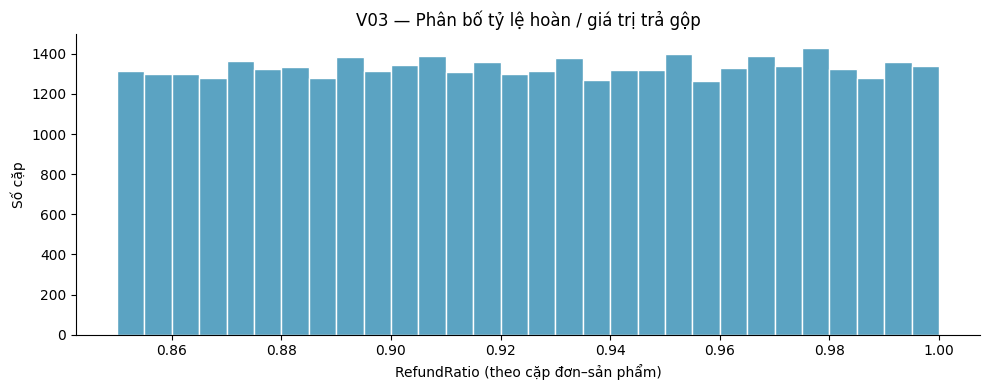

In [11]:
metric_table(metrics, ['returns_rows', 'return_orders', 'return_pairs', 'returned_orders_without_returns',
                       'full_return_pairs', 'partial_return_pairs', 'over_return_pairs',
                       'refund', 'refund_orders_above_payment', 'refund_above_net_return',
                       'refund_ratio_mean', 'pearson_refund_ratio_discount_rate'])
table(reports['comparisons'], 'Kiểm tra theo đúng cấp bản ghi/cặp/đơn',
      ['section', 'comparison', 'compared_cases', 'matched_cases', 'mismatched_cases',
       'tolerance', 'direction'], limit=12)
table(demo, 'Minh họa công thức trên cặp đã cộng từ nguồn',
      ['order_id', 'product_id', 'returned_quantity', 'purchased_quantity', 'refund',
       'GrossReturn tính lại', 'NetReturn tính lại'], limit=5)
table(reports['cutoff_summary'], 'Độ phủ cuối kỳ của nhóm đơn returned chưa có chi tiết',
      ['missing_detail_orders', 'first_missing_order_date', 'last_missing_order_date',
       'missing_after_last_return', 'missing_within_observed_max_lag'])
table(exceptions['refund_above_payment'], 'Ví dụ hoàn tích lũy vượt tiền thanh toán', limit=5)
fig, ax = plt.subplots()
ax.hist(ledgers['pairs'].refund_ratio.dropna().map(float), bins=30, color='#5ba3c2', edgecolor='white')
ax.set(title='V03 — Phân bố tỷ lệ hoàn / giá trị trả gộp', xlabel='RefundRatio (theo cặp đơn–sản phẩm)', ylabel='Số cặp')
finish_figure(fig)
del sources, ledgers, distributions, reports, exceptions, dated_returns, lag, demo, fingerprints
gc.collect();

**Nhận xét và ý nghĩa:** đã có phát hiện về đơn mang trạng thái `returned` thiếu chi tiết, hoàn tích lũy vượt thanh toán và không khớp giả thuyết hoàn theo giá gộp/net.
Cần đối soát chính sách hoàn tiền và luồng dữ liệu, không tự sửa các giá trị. Các cặp trả một phần cần so với lượng mua tích lũy thay vì từng dòng mua.

**Chưa xác minh:** phí, thời điểm quyết toán, lô hàng thực sự trả và cách phân bổ giảm giá.
Cửa sổ cuối kỳ chỉ là mô tả, chưa chứng minh nguyên nhân thiếu chi tiết là kiểm duyệt phải hoặc dữ liệu cuối kỳ chưa đầy đủ.
Pearson gần 0 không chứng minh độc lập, sinh ngẫu nhiên hoặc không có liên hệ phi tuyến.


## 4. V04 — Lượng bán tồn kho và giao dịch theo tháng

**Mục tiêu:** xác định `inventory.units_sold` có bằng lượng hàng bán cộng từ giao dịch theo sản phẩm–tháng không, đồng thời kiểm tra độ phủ hai phía.

**Bảng:** `inventory.csv` (snapshot, năm/tháng, sản phẩm, lượng bán), `orders.csv` (ngày/trạng thái), `order_items.csv` (sản phẩm, số lượng).

**Phương pháp:** `check_v04_inventory_sales.read_sources/analyze`; khóa tháng là `YYYY-MM` lấy từ ngày.
Kiểm tra năm/tháng khai báo khớp snapshot, một dòng inventory/cặp và FK đơn; cộng giao dịch trước outer join `one_to_one`.

$$T_{p,m}=\sum_{i:\ product_i=p,\ month(order_i)=m}quantity_i,\quad
\Delta_{p,m}=units\_sold_{p,m}-T_{p,m}.$$
$$RelativeDiff=\Delta/T,\quad WARE=\sum|\Delta|/\sum|T|.$$

Chỉ tính sai lệch/Pearson trên giao hai nguồn; mẫu số 0 cho kết quả chưa xác định. Cặp chỉ có ở một bên giữ NULL, không điền 0.
Phép tính chính dùng tất cả trạng thái; số dòng hàng, số đơn khác nhau và lượng theo trạng thái là đối chiếu nhạy cảm với định nghĩa.


In [12]:
v = modules['V04']
sources = v.read_sources(paths_for('V04'))
metrics, checks, ledgers, reports, fingerprints = v.analyze(**sources)
examples, coverage = v.compact_examples(ledgers['quantity'], EXAMPLES_LIMIT)
reports['example_coverage'] = pd.DataFrame(coverage)
register('V04', metrics, reports, checks)

transaction_rows = sources['order_items'][['order_id', 'product_id', 'quantity']].merge(
    sources['orders'][['order_id', 'order_date']], on='order_id', how='left', validate='many_to_one')
transaction_rows['month'] = pd.to_datetime(transaction_rows.order_date, format='%Y-%m-%d').dt.strftime('%Y-%m')
transaction_rows['quantity'] = v.integer_values(transaction_rows.quantity, 'quantity')
by_pair = transaction_rows.groupby(['product_id', 'month']).quantity.sum()
verify_illustration('V04', 'tổng lượng giao dịch nguồn', int(by_pair.sum()), metrics['transaction_quantity_total'])
verify_illustration('V04', 'số cặp sản phẩm–tháng giao dịch', len(by_pair), metrics['transaction_pairs'])
both = ledgers['quantity'].query("coverage == 'both'")
verify_illustration('V04', 'số cặp bằng nhau', int((both.inventory_units - both.transaction_value).eq(0).sum()),
                    metrics['equal_pairs'])

,Chỉ tiêu,Tính từ CSV
0,union_pairs,"60,941.000000"
1,both_pairs,"56,615.000000"
2,inventory_only_pairs,"3,632.000000"
3,transactions_only_pairs,694.000000
4,equal_pairs,"1,716.000000"
5,inventory_greater_pairs,771.000000
6,inventory_lower_pairs,"54,128.000000"
7,pearson,0.989704
8,mean_signed_difference,-40.365557
9,weighted_absolute_relative_difference,0.712679


Các định nghĩa lượng giao dịch được thử — mỗi dòng có độ phủ riêng — hiển thị 9/9 dòng tổng hợp/ví dụ


,metric,status,both_pairs,equal_pairs,mean_signed_difference,pearson
0,quantity,None,56615,1716,-40.365557,0.989704
1,item_rows,None,56615,16819,3.719120,0.992960
2,distinct_orders,None,56615,16821,3.719403,0.992959
3,status_quantity_0,cancelled,25551,1012,18.228641,0.849502
4,status_quantity_1,created,6415,138,43.978644,0.378500
5,status_quantity_2,delivered,53965,1922,-30.445011,0.985490
6,status_quantity_3,paid,10419,233,38.188022,0.530412
7,status_quantity_4,returned,19694,642,25.299431,0.764983
8,status_quantity_5,shipped,10511,260,37.430311,0.552935


Ví dụ chênh lệch tuyệt đối lớn — hiển thị 5/20 dòng tổng hợp/ví dụ


,product_id,month,inventory_units,transaction_value,difference
0,786,2012-12,670,2502,-1832
1,785,2012-12,670,2447,-1777
2,792,2013-12,659,2176,-1517
3,791,2014-12,580,2036,-1456
4,791,2013-12,659,2087,-1428


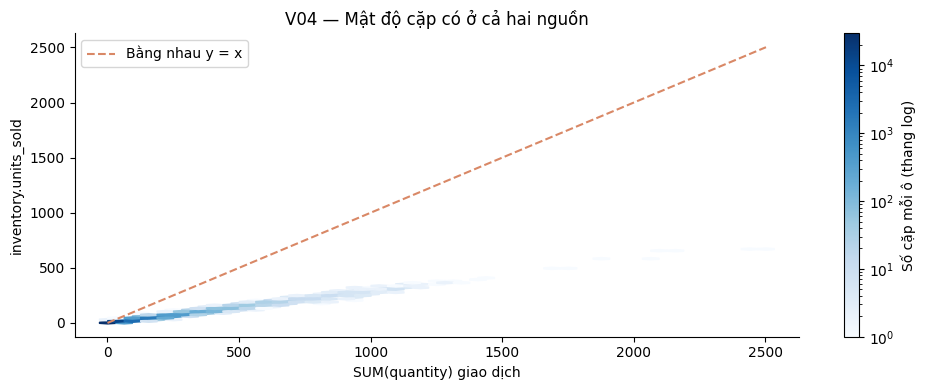

In [13]:
metric_table(metrics, ['union_pairs', 'both_pairs', 'inventory_only_pairs', 'transactions_only_pairs',
                       'equal_pairs', 'inventory_greater_pairs', 'inventory_lower_pairs', 'pearson',
                       'mean_signed_difference', 'weighted_absolute_relative_difference'])
table(reports['comparisons'], 'Các định nghĩa lượng giao dịch được thử — mỗi dòng có độ phủ riêng',
      ['metric', 'status', 'both_pairs', 'equal_pairs', 'mean_signed_difference', 'pearson'], limit=12)
table(examples['largest_absolute_differences'], 'Ví dụ chênh lệch tuyệt đối lớn',
      ['product_id', 'month', 'inventory_units', 'transaction_value', 'difference'], limit=5)
fig, ax = plt.subplots()
x = both.transaction_value.astype(float)
y = both.inventory_units.astype(float)
hb = ax.hexbin(x, y, gridsize=40, mincnt=1, bins='log', cmap='Blues')
bound = max(float(x.max()), float(y.max()))
ax.plot([0, bound], [0, bound], '--', color='#d98866', label='Bằng nhau y = x')
fig.colorbar(hb, ax=ax, label='Số cặp mỗi ô (thang log)')
ax.set(title='V04 — Mật độ cặp có ở cả hai nguồn', xlabel='SUM(quantity) giao dịch', ylabel='inventory.units_sold')
ax.legend()
finish_figure(fig)
del sources, ledgers, reports, examples, coverage, transaction_rows, by_pair, both, x, y, fingerprints
gc.collect();

**Nhận xét và ý nghĩa:** hệ số tương quan cao cùng nhiều cặp chênh lệch là hai quan sát tương thích; tương quan không chứng minh hai đại lượng bằng nhau.
Không dùng `units_sold` thay thế tổng quantity hoặc suy ngược lượng bán khi chưa thống nhất định nghĩa và phạm vi danh mục.

**Chưa xác minh:** định nghĩa nghiệp vụ `units_sold`, quy tắc ghi nhận theo trạng thái và nguyên nhân thiếu cặp.
Một cặp vắng mặt chưa chứng minh không có hoạt động. Tổng lượng, số dòng và số đơn có đơn vị khác nhau; các phép thử theo trạng thái không xác nhận quy tắc loại đơn.


## 5. V05 — Khả năng sử dụng `reorder_flag`

**Mục tiêu:** kiểm tra miền nhị phân, NULL, độ biến thiên của nhãn, khả năng phân biệt hai lớp và quan hệ mô tả với chỉ báo tồn kho.

**Bảng:** `inventory.csv`; trọng tâm `reorder_flag`, `stock_on_hand`, `days_of_supply`, `stockout_flag`, `stockout_days`, `overstock_flag`.

**Phương pháp:** `check_v05_reorder_flag.read_source/analyze`; tách `0`, `1`, `NULL`, `invalid` bằng parser Decimal hiện có.
Trên nhãn nhị phân hợp lệ, $p_k=N_k/(N_0+N_1)$:

$$H=-\sum_{k:p_k>0}p_k\log_2p_k;\qquad MajorityFraction=\max(p_0,p_1).$$

Các điều kiện `days_of_supply<=30`, `stock_on_hand<=5/10`, cờ thiếu/dư hàng chỉ dùng thăm dò và có thể chồng lấp.
Tỷ lệ lớp 1 dùng mẫu số nhãn nhị phân hợp lệ trong nhóm. Predictor thiếu/không hợp lệ được ghi chưa biết, không tự chuyển thành false.
Pearson với biến hằng là không xác định, không gán 0.


In [14]:
v = modules['V05']
inventory = v.read_source(paths_for('V05')['inventory'])
metrics, reports, fingerprint, records = v.analyze(inventory)
checks = {
    'distribution_partitions_all_rows': int(reports['reorder_distribution'].rows.sum()) == len(inventory),
    'condition_groups_cover_eligible_and_unknown': all(
        row.selected_rows + row.not_selected_rows + row.unknown_predictor_rows == len(inventory)
        for row in reports['condition_summary'].itertuples()),
}
register('V05', metrics, reports, checks)

parsed = inventory.reorder_flag.map(v.number)
categories = parsed.map(lambda pair: v.flag_category(*pair))
counts = categories.value_counts().reindex(['0', '1', 'NULL', 'invalid'], fill_value=0)
valid_counts = counts[['0', '1']]
probs = valid_counts / valid_counts.sum()
entropy = -sum(float(p) * math.log2(float(p)) for p in probs if p > 0)
verify_illustration('V05', 'số nhãn 0 từ nguồn', int(counts['0']), metrics['reorder_zero_rows'])
verify_illustration('V05', 'entropy nhị phân', entropy, metrics['binary_entropy_bits'])
stockout = inventory.stockout_flag.map(v.number).map(lambda pair: pair[1] == 'finite' and pair[0] == 1)
verify_illustration('V05', 'số snapshot stockout_flag=1', int(stockout.sum()), metrics['stockout_flag_eq_1'])

In [15]:
metric_table(metrics, ['inventory_rows', 'binary_class_count', 'is_constant_complete', 'binary_entropy_bits',
                       'majority_class_fraction_valid', 'usable_as_two_class_target_as_is'])
table(reports['reorder_distribution'], 'Phân bố nhãn reorder_flag')
table(reports['condition_summary'], 'Các nhóm thăm dò; không cộng nhóm chồng lấp thành tổng',
      ['condition', 'selected_rows', 'unknown_predictor_rows', 'selected_valid_binary_targets',
       'selected_positive_targets', 'positive_percent_selected_valid_targets'])
table(reports['predictor_correlations'], 'Tương quan và lý do không xác định',
      ['feature', 'paired_rows', 'excluded_rows', 'pearson', 'reason'])
table(inventory.loc[stockout, ['snapshot_date', 'product_id', 'stock_on_hand', 'days_of_supply',
                              'stockout_flag', 'reorder_flag']],
      'Ví dụ có cờ thiếu hàng — chỉ minh họa, không xác nhận nhãn sai', limit=5)
del inventory, reports, records, parsed, categories, counts, valid_counts, probs, stockout
gc.collect();

,Chỉ tiêu,Tính từ CSV
0,inventory_rows,60247
1,binary_class_count,1
2,is_constant_complete,True
3,binary_entropy_bits,-0.000000
4,majority_class_fraction_valid,1.000000
5,usable_as_two_class_target_as_is,False


Phân bố nhãn reorder_flag — hiển thị 4/4 dòng tổng hợp/ví dụ


,reorder_bucket,rows,percent_all
0,0,60247,100.000000
1,1,0,0.000000
2,NULL,0,0.000000
3,invalid,0,0.000000


Các nhóm thăm dò; không cộng nhóm chồng lấp thành tổng — hiển thị 6/6 dòng tổng hợp/ví dụ


,condition,selected_rows,unknown_predictor_rows,selected_valid_binary_targets,selected_positive_targets,positive_percent_selected_valid_targets
0,days_of_supply_le_30,2188,0,2188,0,0.000000
1,stock_on_hand_le_5,5525,0,5525,0,0.000000
2,stock_on_hand_le_10,11622,0,11622,0,0.000000
3,stockout_flag_eq_1,40571,0,40571,0,0.000000
4,stockout_days_gt_0,40571,0,40571,0,0.000000
5,overstock_flag_eq_1,45942,0,45942,0,0.000000


Tương quan và lý do không xác định — hiển thị 5/5 dòng tổng hợp/ví dụ


,feature,paired_rows,excluded_rows,pearson,reason
0,stock_on_hand,60247,0,None,constant_target
1,days_of_supply,60247,0,None,constant_target
2,stockout_flag,60247,0,None,constant_target
3,stockout_days,60247,0,None,constant_target
4,overstock_flag,60247,0,None,constant_target


Ví dụ có cờ thiếu hàng — chỉ minh họa, không xác nhận nhãn sai — hiển thị 5/40571 dòng tổng hợp/ví dụ


,snapshot_date,product_id,stock_on_hand,days_of_supply,stockout_flag,reorder_flag
0,2022-10-31,1,3,90.0,1,0
1,2022-11-30,1,3,90.0,1,0
2,2022-12-31,1,3,90.0,1,0
3,2016-04-30,3,35,95.5,1,0
4,2016-05-31,3,36,108.0,1,0


**Nhận xét và ý nghĩa:** nhãn hoàn chỉnh nhưng chỉ có một lớp không cung cấp thông tin phân biệt quyết định đặt hàng lại.
Tỷ lệ lớp đa số bằng 1 chỉ mô tả cột hằng; chưa phải bằng chứng về mô hình nhị phân hữu ích.
Việc có cờ thiếu hàng trong khi `reorder_flag=0` là câu hỏi về quy trình, chưa chứng minh nhãn bị lỗi.

**Chưa xác minh:** chính sách bổ sung hàng, lead time, ràng buộc nhà cung cấp, thời điểm kích hoạt cờ và các điều kiện ngoài CSV.
Các ngưỡng thăm dò không phải quy tắc chính thức và không được dùng để sinh nhãn thay thế.


## 6. V06 — Mã khuyến mãi, NULL và giảm giá

**Mục tiêu:** kiểm tra NULL ở hai ô mã/nhóm áp dụng, độ phủ tham chiếu, mã kép, dấu của giảm giá và metadata chương trình.

**Bảng:** `order_items.csv` (`promo_id`, `promo_id_2`, `discount_amount`) và `promotions.csv`
(`promo_id`, `promo_type`, `applicable_category`, `start_date`, `end_date`).

**Phương pháp:** `check_v06_promotions.read_sources/analyze`; đọc chuỗi gốc, phân biệt ô rỗng với token NULL rồi dùng `normalized` hiện có.
Mỗi dòng hàng thuộc đúng một nhóm: không mã, chỉ mã 1, chỉ mã 2, cả hai mã.

$$N_{NULL,3\ cột}=N_{NULL,promo\_id}+N_{NULL,promo\_id\_2}+N_{NULL,category}.$$

Đây là **số ô NULL**, không phải số dòng lỗi và không cùng mẫu số giữa hai bảng.
Mỗi mã không NULL được kiểm tra thuộc tập khóa promotions; tổng lượt tham chiếu có thể lớn hơn số dòng có mã.
Giảm giá tách dương/0/âm/NULL/không phải số/không hữu hạn; thời lượng là `end_date-start_date` (không cộng 1).


In [16]:
v = modules['V06']
sources = v.read_sources(paths_for('V06'))
primary = v.analyze(**sources, examples=EXAMPLES_LIMIT)
metrics, reports = primary['metrics'], primary['reports']
register('V06', metrics, reports, primary['checks'])

first = v.normalized(sources['order_items'].promo_id)
second = v.normalized(sources['order_items'].promo_id_2)
category = v.normalized(sources['promotions'].applicable_category)
null_cells = int(first.isna().sum() + second.isna().sum() + category.isna().sum())
known_codes = set(v.normalized(sources['promotions'].promo_id).dropna())
unknown_uses = int((first.notna() & ~first.isin(known_codes)).sum()
                   + (second.notna() & ~second.isin(known_codes)).sum())
verify_illustration('V06', 'số ô NULL của ba cột nguồn', null_cells, metrics['three_fields_null_total'])
verify_illustration('V06', 'dòng có hai mã', int((first.notna() & second.notna()).sum()), metrics['both_codes_rows'])
verify_illustration('V06', 'lượt mã không có trong promotions', unknown_uses, metrics['unknown_reference_uses_total'])

In [17]:
table(reports['null_summary'], 'NULL theo cột — tỷ lệ dùng số dòng của bảng chứa cột',
      ['table', 'column', 'rows', 'null_count', 'null_percent'])
table(reports['code_presence'], 'Bốn nhóm hiện diện mã trên dòng hàng')
table(reports['reference_keys'], 'Độ phủ tham chiếu theo từng ô mã')
table(reports['discount_by_code_presence'], 'Có mã/không mã và trạng thái giảm giá', limit=12)
table(reports['applicable_category'], 'Danh mục áp dụng — giữ NULL chưa rõ nghĩa')
table(reports['duration_days'], 'Thống kê thời lượng chương trình')
table(pd.DataFrame(primary['exceptions']['both_promotion_codes']['records']), 'Ví dụ có hai mã', limit=5)
print(f"Tổng ô NULL ba cột: {null_cells:,}; số dòng có hai mã: {metrics['both_codes_rows']:,}; "
      f"lượt tham chiếu mã không biết: {unknown_uses:,}.")
del sources, primary, reports, first, second, category, known_codes
gc.collect();

NULL theo cột — tỷ lệ dùng số dòng của bảng chứa cột — hiển thị 3/3 dòng tổng hợp/ví dụ


,table,column,rows,null_count,null_percent
0,order_items,promo_id,714669,438353,61.336507
1,order_items,promo_id_2,714669,714463,99.971175
2,promotions,applicable_category,50,40,80.000000


Bốn nhóm hiện diện mã trên dòng hàng — hiển thị 4/4 dòng tổng hợp/ví dụ


,group,rows,percent_all
0,no_code,438353,61.336507
1,only_promo_id,276110,38.634669
2,only_promo_id_2,0,0.000000
3,both_codes,206,0.028825


Độ phủ tham chiếu theo từng ô mã — hiển thị 2/2 dòng tổng hợp/ví dụ


,slot,non_null_uses,distinct_used_codes,known_reference_uses,unknown_reference_uses,distinct_unknown_codes
0,promo_id,276316,50,276316,0,0
1,promo_id_2,206,2,206,0,0


... (5 outputs left out)

,eligible_rows,excluded_rows,minimum,maximum,mean,median,p25,p75
0,50,0,29,45,33.540000,30.500000,30.000000,34.000000


Ví dụ có hai mã — hiển thị 5/20 dòng tổng hợp/ví dụ


,source_row,order_id,product_id,discount_amount,promo_id,promo_id_2
0,280517,320123,2331,3385.57,PROMO-0013,PROMO-0015
1,280519,320125,622,4594.83,PROMO-0013,PROMO-0015
2,280520,320126,565,2976.2,PROMO-0013,PROMO-0015
3,280523,320128,609,989.26,PROMO-0013,PROMO-0015
4,280524,320129,2086,2229.82,PROMO-0013,PROMO-0015


Tổng ô NULL ba cột: 1,152,856; số dòng có hai mã: 206; lượt tham chiếu mã không biết: 0.


**Nhận xét và ý nghĩa:** NULL ở ô mã có thể diễn tả không ghi nhận mã; NULL ở category cần được làm rõ riêng.
Sự phù hợp giữa hiện diện mã và giảm giá trong mẫu là mô tả dữ liệu, chưa xác nhận điều kiện áp dụng hoặc cơ chế cộng dồn khuyến mãi.

**Chưa xác minh:** category NULL có nghĩa áp dụng mọi nhóm hay thiếu metadata; stacking, phân bổ giảm giá và quan hệ với `promotions.discount_value`.
Phần này chỉ dùng hai bảng, không kiểm tra ngày đặt hàng nằm trong thời gian chương trình hay thời điểm thực sự áp dụng mã.
Không điền NULL hoặc thay đổi mã.


## 7. V07 — Phân bố và cách hiểu `bounce_rate`

**Mục tiêu:** kiểm tra miền giá trị, phân bố, lịch ngày, cách diễn giải thang đo và tương quan mô tả với lượng truy cập.

**Bảng:** `web_traffic.csv` (`date`, `bounce_rate`, `sessions`, `unique_visitors`, `page_views`, `avg_session_duration_sec`).

**Phương pháp:** `check_v07_bounce_rate.read_source/analyze`; phân loại NULL, không phải số, không hữu hạn, âm, 0 và ngoài `[0,1]` trước khi tóm tắt giá trị hữu hạn.

$$\bar b=\frac1n\sum b_i,\qquad s=\sqrt{\frac{\sum(b_i-\bar b)^2}{n-1}}.$$

Phân vị nội suy tuyến tính; kiểm tra ngày phân biệt, trùng, thiếu trong khoảng min–max.
**Nếu** `bounce_rate` là phân số thì giá trị hiển thị phần trăm là $100b$, nhưng đây chỉ là minh họa có điều kiện.
`page_views/sessions` và Pearson với biến khác không tái lập tử số bounce.


In [18]:
v = modules['V07']
web = v.read_source(paths_for('V07')['web_traffic'])
primary = v.analyze(web, examples=EXAMPLES_LIMIT)
metrics, reports = primary['metrics'], primary['reports']
register('V07', metrics, reports, primary['checks'])

parsed = web.bounce_rate.map(v.number)
finite = pd.Series([float(value) for value, state in parsed if state == 'finite'], dtype=float)
verify_illustration('V07', 'trung bình giá trị nguồn hữu hạn', float(finite.mean()), metrics['bounce_mean'])
verify_illustration('V07', 'giá trị nguồn trong [0,1]', int(finite.between(0, 1).sum()), metrics['bounce_in_unit_interval_rows'])
conditional_scale = pd.DataFrame({
    'Thống kê': ['Min', 'Trung bình', 'Max'],
    'Giá trị lưu trữ': [finite.min(), finite.mean(), finite.max()],
})
conditional_scale['% nếu lưu dạng phân số'] = conditional_scale['Giá trị lưu trữ'] * 100

,Chỉ tiêu,Tính từ CSV
0,rows,3652
1,bounce_null_rows,0
2,bounce_non_numeric_rows,0
3,bounce_non_finite_rows,0
4,bounce_distinct_finite,261
5,bounce_min,0.003200
6,bounce_mean,0.004487
7,bounce_max,0.005800
8,duplicate_dates,0
9,missing_calendar_days,0


Hai cách hiển thị — cột % chỉ đúng dưới giả thiết phân số — hiển thị 3/3 dòng tổng hợp/ví dụ


,Thống kê,Giá trị lưu trữ,% nếu lưu dạng phân số
0,Min,0.003200,0.320000
1,Trung bình,0.004487,0.448729
2,Max,0.005800,0.580000


Pearson mô tả; không suy ra công thức bounce — hiển thị 4/4 dòng tổng hợp/ví dụ


,feature,paired_rows,excluded_rows,reason,pearson
0,sessions,3652,0,defined,-0.004614
1,unique_visitors,3652,0,defined,-0.001950
2,page_views,3652,0,defined,0.010369
3,avg_session_duration_sec,3652,0,defined,0.006570


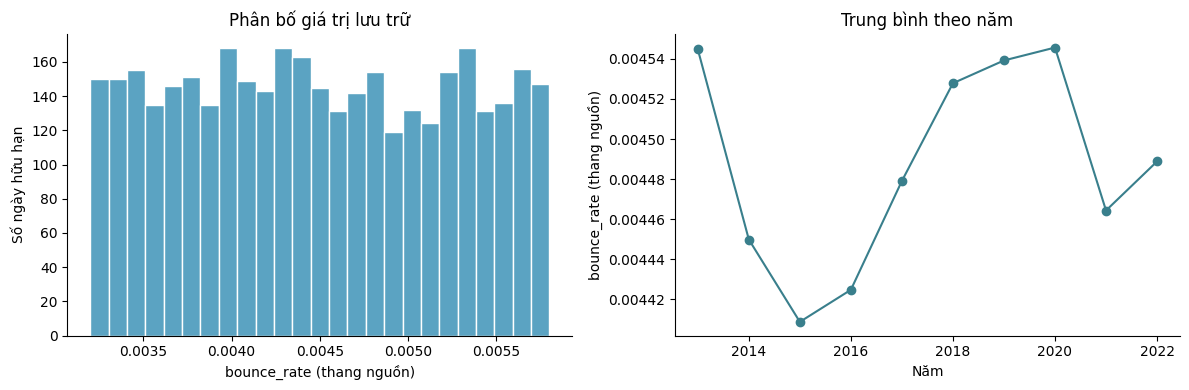

In [19]:
metric_table(metrics, ['rows', 'bounce_null_rows', 'bounce_non_numeric_rows', 'bounce_non_finite_rows',
                       'bounce_distinct_finite', 'bounce_min', 'bounce_mean', 'bounce_max',
                       'duplicate_dates', 'missing_calendar_days', 'complete_one_record_per_calendar_day'])
table(conditional_scale, 'Hai cách hiển thị — cột % chỉ đúng dưới giả thiết phân số')
table(reports['descriptive_correlations'], 'Pearson mô tả; không suy ra công thức bounce')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(finite, bins=25, color='#5ba3c2', edgecolor='white')
axes[0].set(title='Phân bố giá trị lưu trữ', xlabel='bounce_rate (thang nguồn)', ylabel='Số ngày hữu hạn')
dates, states = modules['V06'].strict_dates(web.date)
trend = pd.DataFrame({'date': dates, 'bounce': pd.Series(
    [float(value) if state == 'finite' else None for value, state in parsed])})
yearly = trend.dropna().assign(nam=lambda f: f.date.dt.year).groupby('nam').bounce.mean()
yearly.plot(marker='o', ax=axes[1], color='#397f8c')
axes[1].set(title='Trung bình theo năm', xlabel='Năm', ylabel='bounce_rate (thang nguồn)')
finish_figure(fig)
del web, primary, reports, parsed, finite, dates, states, trend, yearly, conditional_scale
gc.collect();

**Nhận xét và ý nghĩa:** giá trị nằm trong `[0,1]` tương thích về số học với tỷ lệ phân số; trung bình thấp chưa chứng minh sai đơn vị hoặc lỗi thu thập.
Hiểu nhầm phân số và phần trăm làm mức báo cáo/ngưỡng lệch 100 lần. Biểu đồ giữ thang nguồn, không tự đổi dữ liệu.

**Chưa xác minh:** đơn vị chính thức, tử số/mẫu số, định nghĩa sự kiện hoặc phiên, quy tắc tổng hợp và công thức sinh chỉ tiêu.
Chưa đánh giá tính hữu ích dự báo, độ ổn định ngoài mẫu, rò rỉ hoặc tính phù hợp của biến.


## 8. V08 — Nhãn nguồn truy cập theo ngày

**Mục tiêu:** kiểm tra chất lượng nhãn, một nhãn/ngày, phân bố theo năm, lần đổi nhãn, chuỗi liên tiếp và vốn từ với kênh thu hút khách.

**Bảng:** `web_traffic.csv` (`date`, `traffic_source`) và `customers.csv` (`customer_id`, `acquisition_channel`).
Hai bảng có đơn vị quan sát khác nhau: ngày và khách hàng. Không nối khách–ngày để suy diễn nguồn phiên.

**Phương pháp:** dùng `check_v08_traffic_source.analyze` với bộ đọc chuỗi của V06.
Chỉ ngày hợp lệ, không trùng, có nhãn dùng được mới vào timeline; khoảng trống ngày ngắt chuỗi.

$$Change_t=1(date_t-date_{t-1}=1\ ngày)\,1(label_t\ne label_{t-1}),$$
$$RunCount=\sum Change_t+CalendarSegments;\qquad
Tỷ\ lệ\ ngày_l=100\,Days_l/EligibleDays.$$

So sánh tập tên nhãn chính xác giữa hai bảng, không coi tên giống nhau là ngữ nghĩa giống nhau.
Tần suất nhãn theo ngày không có mẫu số phiên, do đó không phải thị phần traffic.


In [20]:
v = modules['V08']
sources = modules['V06'].read_sources(paths_for('V08'))
primary = v.analyze(**sources, examples=EXAMPLES_LIMIT)
metrics, reports = primary['metrics'], primary['reports']
register('V08', metrics, reports, primary['checks'])

web = sources['web_traffic']
dates, states = modules['V06'].strict_dates(web.date)
label_states = web.traffic_source.map(v.label_state)
eligible = states.eq('valid') & ~dates.duplicated(keep=False) & label_states.isin(v.USABLE)
timeline = pd.DataFrame({'date': dates[eligible], 'label': web.loc[eligible, 'traffic_source']}).sort_values('date')
adjacent = timeline.date.diff().dt.days.eq(1)
changed = adjacent & timeline.label.ne(timeline.label.shift())
verify_illustration('V08', 'đổi nhãn giữa ngày liên tiếp từ nguồn', int(changed.sum()), metrics['label_changes'])
verify_illustration('V08', 'độ dài timeline hợp lệ', len(timeline), metrics['eligible_days'])
verify_illustration('V08', 'đồng nhất tập tên nhãn',
                    set(modules['V06'].normalized(web.traffic_source).dropna()) ==
                    set(modules['V06'].normalized(sources['customers'].acquisition_channel).dropna()),
                    metrics['label_sets_equal'])

,Chỉ tiêu,Tính từ CSV
0,eligible_days,3652
1,excluded_web_rows,0
2,consecutive_calendar_pairs,3651
3,label_changes,2951
4,unchanged_pairs,700
5,calendar_segments,1
6,run_count,2952
7,longest_run_days,7
8,label_sets_equal,True


Số ngày mang từng nhãn — không phải số phiên — hiển thị 6/6 dòng tổng hợp/ví dụ


,label,days,percent_eligible_days
0,direct,266,7.283680
1,email_campaign,505,13.828039
2,organic_search,1090,29.846659
3,paid_search,784,21.467689
4,referral,375,10.268346
5,social_media,632,17.305586


Số khách mang từng nhãn — mẫu số khác số ngày — hiển thị 6/6 dòng tổng hợp/ví dụ


,label,rows,percent_rows
0,direct,9803,8.039859
1,email_campaign,14674,12.034774
2,organic_search,36450,29.894202
3,paid_search,24285,19.917166
4,referral,12270,10.063151
5,social_media,24448,20.050849


Ví dụ chuỗi nhãn dài nhất — hiển thị 1/1 dòng tổng hợp/ví dụ


,label,start_date,end_date,length_days
0,organic_search,2013-10-09,2013-10-15,7


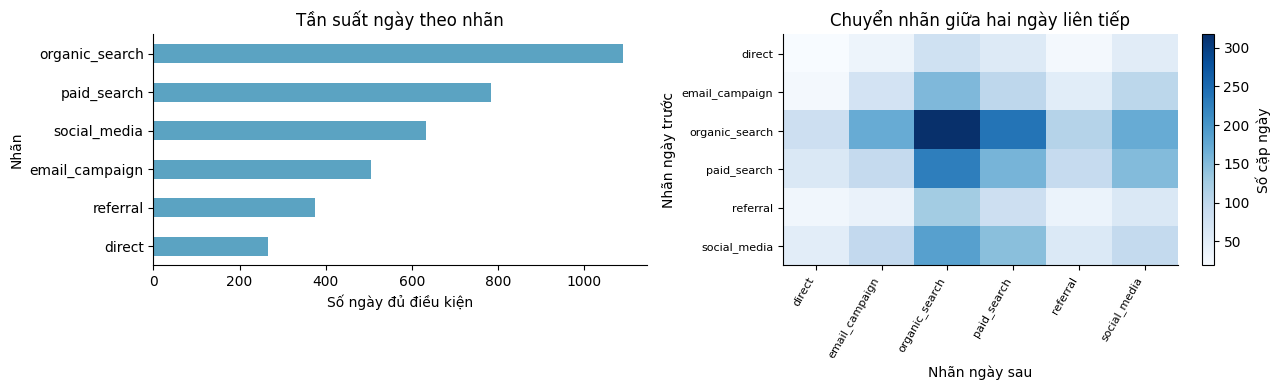

In [21]:
metric_table(metrics, ['eligible_days', 'excluded_web_rows', 'consecutive_calendar_pairs', 'label_changes',
                       'unchanged_pairs', 'calendar_segments', 'run_count', 'longest_run_days', 'label_sets_equal'])
table(reports['daily_distribution'], 'Số ngày mang từng nhãn — không phải số phiên')
table(reports['customer_label_rows'], 'Số khách mang từng nhãn — mẫu số khác số ngày')
table(pd.DataFrame(primary['exceptions']['longest_runs']['records']), 'Ví dụ chuỗi nhãn dài nhất', limit=5)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
reports['daily_distribution'].set_index('label').days.sort_values().plot.barh(ax=axes[0], color='#5ba3c2')
axes[0].set(title='Tần suất ngày theo nhãn', xlabel='Số ngày đủ điều kiện', ylabel='Nhãn')
matrix = reports['transitions'].pivot(index='from_label', columns='to_label', values='pairs').fillna(0)
im = axes[1].imshow(matrix.values, cmap='Blues', aspect='auto')
axes[1].set_xticks(range(len(matrix.columns)), matrix.columns, rotation=60, ha='right', fontsize=8)
axes[1].set_yticks(range(len(matrix.index)), matrix.index, fontsize=8)
axes[1].set(title='Chuyển nhãn giữa hai ngày liên tiếp', xlabel='Nhãn ngày sau', ylabel='Nhãn ngày trước')
fig.colorbar(im, ax=axes[1], label='Số cặp ngày')
finish_figure(fig)
del sources, web, primary, reports, dates, states, label_states, eligible, timeline, adjacent, changed, matrix
gc.collect();

**Nhận xét và ý nghĩa:** tần suất ngày và chuỗi liên tiếp mô tả cách nhãn xuất hiện theo thời gian.
Vốn từ trùng nhau hỗ trợ kiểm tra tính nhất quán tên gọi; chưa cho phép phân bổ doanh thu hoặc nối một ngày với từng khách.

**Chưa xác minh:** `traffic_source` có là nguồn chi phối hay đại diện mọi phiên trong ngày, cơ cấu phiên thực tế, liên kết từng khách và ngữ nghĩa chung của hai loại nhãn.
Thời điểm xác định/cung cấp nhãn chưa rõ; dùng để dự báo cần kiểm tra thông tin có sẵn tại thời điểm dự báo và nguy cơ rò rỉ.


## 9. V09 — Mẫu nộp bài và khoảng dự báo

**Mục tiêu:** kiểm tra cấu trúc mẫu, kiểu số, lịch ngày tương lai, ngày nhuận, thứ tự dòng và quan hệ thời gian với lịch sử.

**Bảng:** `sample_submission.csv` và `sales.csv`; cột mong đợi theo đúng thứ tự `Date`, `Revenue`, `COGS`.
Ý nghĩa đích lịch sử kế thừa V02 đã tính lại trong notebook; không dùng giá trị mẫu làm nhãn tương lai.

**Phương pháp:** `check_v09_submission.analyze` với bộ đọc chuỗi V06; parse ngày ISO nghiêm ngặt, kiểm tra trùng ngày/dòng,
miền giá trị hữu hạn và lịch đầy đủ trong khoảng quan sát. Không sắp xếp lại dữ liệu nguồn để che mất lỗi thứ tự.

$$H_{calendar}=(max(Date_{sample})-min(Date_{sample})).days+1,$$
$$Gap=(min(Date_{sample})-max(Date_{sales})).days,\quad
Overlap=|Dates_{sample}\cap Dates_{sales}|.$$

Phân biệt độ dài lịch với số dòng nếu có ngày thiếu hoặc trùng. Đọc–ghi–đọc CSV **trong bộ nhớ** để kiểm tra bảo toàn header, giá trị và thứ tự Date;
không xuất file dự báo. Quy tắc nhuận theo lịch Gregorian; ngày nhuận được kiểm tra, không tự thêm dòng.


In [22]:
v = modules['V09']
sources = modules['V06'].read_sources(paths_for('V09'))
primary = v.analyze(**sources, examples=EXAMPLES_LIMIT)
metrics, reports = primary['metrics'], primary['reports']
register('V09', metrics, reports, primary['checks'])

future, future_states = modules['V06'].strict_dates(sources['sample_submission'].Date)
history, history_states = modules['V06'].strict_dates(sources['sales'].Date)
horizon_days = (future.max() - future.min()).days + 1
gap_days = (future.min() - history.max()).days
overlap = len(set(future.dropna()) & set(history.dropna()))
verify_illustration('V09', 'độ dài lịch tương lai kể hai đầu', horizon_days, metrics['sample_expected_calendar_days'])
verify_illustration('V09', 'khoảng cách lịch sử–mẫu', gap_days, metrics['history_to_forecast_start_days'])
verify_illustration('V09', 'số ngày trùng lịch sử–mẫu', overlap, metrics['shared_dates'])

Lịch lịch sử và mẫu tương lai — hiển thị 2/2 dòng tổng hợp/ví dụ


,table,rows,date_min,date_max,distinct_dates,missing_calendar_days,duplicate_dates,original_rows_daily_ascending
0,sample_submission,548,2023-01-01,2024-07-01,548,0,0,True
1,sales,3833,2012-07-04,2022-12-31,3833,0,0,True


Tính chất số của Revenue/COGS — không xác nhận giá trị thật tương lai — hiển thị 4/4 dòng tổng hợp/ví dụ


,table,target,finite_rows,negative_rows,minimum,maximum,distinct_finite,observed_pattern
0,sample_submission,Revenue,548,0,977332.85,9283416.97,548,varying_finite_values
1,sample_submission,COGS,548,0,790258.95,8341542.36,548,varying_finite_values
2,sales,Revenue,3833,0,279813.94,20905271.35,3833,varying_finite_values
3,sales,COGS,3833,0,236576.31,16535857.67,3833,varying_finite_values


Ngày nhuận trong từng khoảng quan sát — hiển thị 3/3 dòng tổng hợp/ví dụ


,table,year,date,present
0,sample_submission,2024,2024-02-29,True
1,sales,2016,2016-02-29,True
2,sales,2020,2020-02-29,True


,Kiểm tra bộ nhớ,Bảo toàn
0,column_order_preserved,True
1,row_count_preserved,True
2,ordered_date_lexemes_preserved,True
3,all_decoded_values_preserved,True


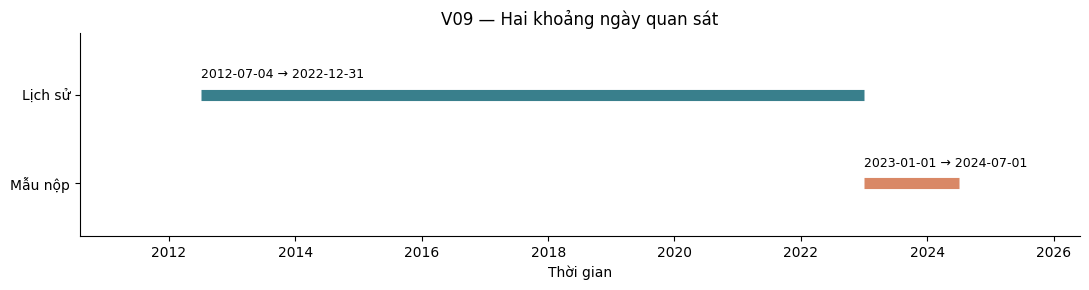

Lịch mẫu: 548 ngày; cách ngày lịch sử cuối 1 ngày; giao lịch: 0 ngày.


In [23]:
table(reports['dates'], 'Lịch lịch sử và mẫu tương lai',
      ['table', 'rows', 'date_min', 'date_max', 'distinct_dates', 'missing_calendar_days',
       'duplicate_dates', 'original_rows_daily_ascending'])
table(reports['target_values'], 'Tính chất số của Revenue/COGS — không xác nhận giá trị thật tương lai',
      ['table', 'target', 'finite_rows', 'negative_rows', 'minimum', 'maximum', 'distinct_finite', 'observed_pattern'])
table(reports['leap_days'], 'Ngày nhuận trong từng khoảng quan sát')
roundtrip = primary['template_memory_roundtrip']
display(pd.DataFrame([{'Kiểm tra bộ nhớ': name, 'Bảo toàn': roundtrip[name]} for name in
                     ['column_order_preserved', 'row_count_preserved', 'ordered_date_lexemes_preserved',
                      'all_decoded_values_preserved']]))
fig, ax = plt.subplots(figsize=(11, 3))
for y, dates, label, color in [(1, history, 'sales: lịch sử', '#397f8c'),
                               (0, future, 'sample_submission: lịch tương lai', '#d98866')]:
    ax.plot([dates.min(), dates.max()], [y, y], linewidth=8, solid_capstyle='butt', color=color)
    ax.annotate(f'{dates.min().date()} → {dates.max().date()}', (dates.min(), y),
                xytext=(0, 12), textcoords='offset points', fontsize=9)
ax.set_yticks([0, 1], ['Mẫu nộp', 'Lịch sử'])
ax.set(title='V09 — Hai khoảng ngày quan sát', xlabel='Thời gian', ylim=(-0.6, 1.7))
ax.margins(x=.16)
finish_figure(fig)
print(f'Lịch mẫu: {horizon_days:,} ngày; cách ngày lịch sử cuối {gap_days} ngày; giao lịch: {overlap} ngày.')
del sources, primary, reports, future, history, future_states, history_states, roundtrip, dates
gc.collect();

**Nhận xét và ý nghĩa:** mẫu xác định lịch và cấu trúc đầu ra; các giá trị Revenue/COGS có thể khác 0, biến thiên và vẫn không phải nhãn thật đã xác minh.
V02 hỗ trợ hiểu Revenue lịch sử theo giá trị gộp và COGS theo giá vốn cung cấp. Hai lịch tách nhau không đủ chứng minh toàn bộ pipeline không rò rỉ.

**Chưa xác minh:** nguồn gốc giá trị mẫu, nhãn tương lai thực, đơn vị tiền chính thức, scoring, độ chính xác số khi nộp và các ràng buộc cuộc thi khác.
Roundtrip bộ nhớ chỉ bảo toàn cấu trúc/giá trị giải mã, không cam kết giống từng byte và không kiểm tra pipeline xuất dự báo sau này.
Chưa xác minh khả năng có sẵn các biến ngoại sinh tương lai. Không huấn luyện, tạo đặc trưng hoặc tính MAE/RMSE/R².


## 10. Tổng hợp kết quả và giới hạn

Bảng cuối tóm tắt số chỉ tiêu, số bảng và số phép kiểm đã hoàn tất cho V01–V09. Các phép tính minh họa cho thấy cách đi từ CSV đến kết quả.

Cuối lượt chạy, notebook kiểm tra lại SHA-256 của các CSV đã dùng. Nếu CSV bị sửa hoặc xóa trong lúc chạy, thông báo sẽ nêu tên tệp.

In [24]:
assert set(results) == set(modules), 'Chưa chạy đủ V01–V09'
source_after = source_snapshot()
changed_csvs = [
    name for name, sha in source_before.items() if source_after.get(name) != sha
]
if changed_csvs:
    raise RuntimeError('CSV nguồn thay đổi hoặc bị thiếu trong lúc chạy: ' + ', '.join(changed_csvs))

summary = pd.DataFrame(results.values())
table(summary, 'Kết quả kiểm chứng V01–V09', limit=9)
display(pd.DataFrame([{
    'Mục hoàn tất': len(summary),
    'Chỉ tiêu đã tính': int(summary['Chỉ tiêu đã tính'].sum()),
    'Bảng đã tính': int(summary['Bảng đã tính'].sum()),
    'Phép tính minh họa khớp': len(illustration_checks),
}]))
print('Đã kiểm chứng đủ chín câu hỏi từ dữ liệu gốc.')

Kết quả kiểm chứng V01–V09 — hiển thị 9/9 dòng tổng hợp/ví dụ


,Mục,Chỉ tiêu đã tính,Bảng đã tính,Phép kiểm kỹ thuật đạt
0,V01,40,4,8
1,V02,20,9,15
2,V03,48,16,6
3,V04,48,9,5
4,V05,22,7,2
5,V06,40,10,5
6,V07,38,7,5
7,V08,54,10,10
8,V09,63,5,7


,Mục hoàn tất,Chỉ tiêu đã tính,Bảng đã tính,Phép tính minh họa khớp
0,9,373,77,27


Đã kiểm chứng đủ chín câu hỏi từ dữ liệu gốc.
